In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("Task_dataset_customer_shopping_data.csv")

print(train.head().to_string())

  invoice_no customer_id  gender  age  category  quantity    price payment_method invoice_date   shopping_mall
0    I138884     C241288  Female   28  Clothing         5  1500.40    Credit Card     5/8/2022          Kanyon
1    I317333     C111565    Male   21     Shoes         3  1800.51     Debit Card   12/12/2021  Forum Istanbul
2    I127801     C266599    Male   20  Clothing         1   300.08           Cash    9/11/2021       Metrocity
3    I173702     C988172  Female   66     Shoes         5  3000.85    Credit Card   16/05/2021    Metropol AVM
4    I337046     C189076  Female   53     Books         4    60.60           Cash   24/10/2021          Kanyon


In [12]:
print(train.tail().to_string())

      invoice_no customer_id  gender  age         category  quantity    price payment_method invoice_date     shopping_mall
99452    I219422     C441542  Female   45         Souvenir         5    58.65    Credit Card   21/09/2022            Kanyon
99453    I325143     C569580    Male   27  Food & Beverage         2    10.46           Cash   22/09/2021    Forum Istanbul
99454    I824010     C103292    Male   63  Food & Beverage         2    10.46     Debit Card   28/03/2021         Metrocity
99455    I702964     C800631    Male   56       Technology         4  4200.00           Cash   16/03/2021      Istinye Park
99456    I232867     C273973  Female   36         Souvenir         3    35.19    Credit Card   15/10/2022  Mall of Istanbul


In [13]:
print(train.shape)

(99457, 10)


In [14]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      99457 non-null  object 
 1   customer_id     99457 non-null  object 
 2   gender          99457 non-null  object 
 3   age             99457 non-null  int64  
 4   category        99457 non-null  object 
 5   quantity        99457 non-null  int64  
 6   price           99457 non-null  float64
 7   payment_method  99457 non-null  object 
 8   invoice_date    99457 non-null  object 
 9   shopping_mall   99457 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 7.6+ MB


In [15]:
print(train.describe().to_string())

                age      quantity         price
count  99457.000000  99457.000000  99457.000000
mean      43.427089      3.003429    689.256321
std       14.990054      1.413025    941.184567
min       18.000000      1.000000      5.230000
25%       30.000000      2.000000     45.450000
50%       43.000000      3.000000    203.300000
75%       56.000000      4.000000   1200.320000
max       69.000000      5.000000   5250.000000


In [17]:
print(train.columns)

Index(['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity',
       'price', 'payment_method', 'invoice_date', 'shopping_mall'],
      dtype='object')


In [18]:
print(train.isnull().sum().to_string())

invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment_method    0
invoice_date      0
shopping_mall     0


In [19]:
print(train.dtypes.to_string())

invoice_no         object
customer_id        object
gender             object
age                 int64
category           object
quantity            int64
price             float64
payment_method     object
invoice_date       object
shopping_mall      object


In [23]:
print(train['category'].unique())

['Clothing' 'Shoes' 'Books' 'Cosmetics' 'Food & Beverage' 'Toys'
 'Technology' 'Souvenir']


In [ ]:
print(train['category'].value_counts())

category
Clothing           34487
Cosmetics          15097
Food & Beverage    14776
Toys               10087
Shoes              10034
Souvenir            4999
Technology          4996
Books               4981
Name: count, dtype: int64


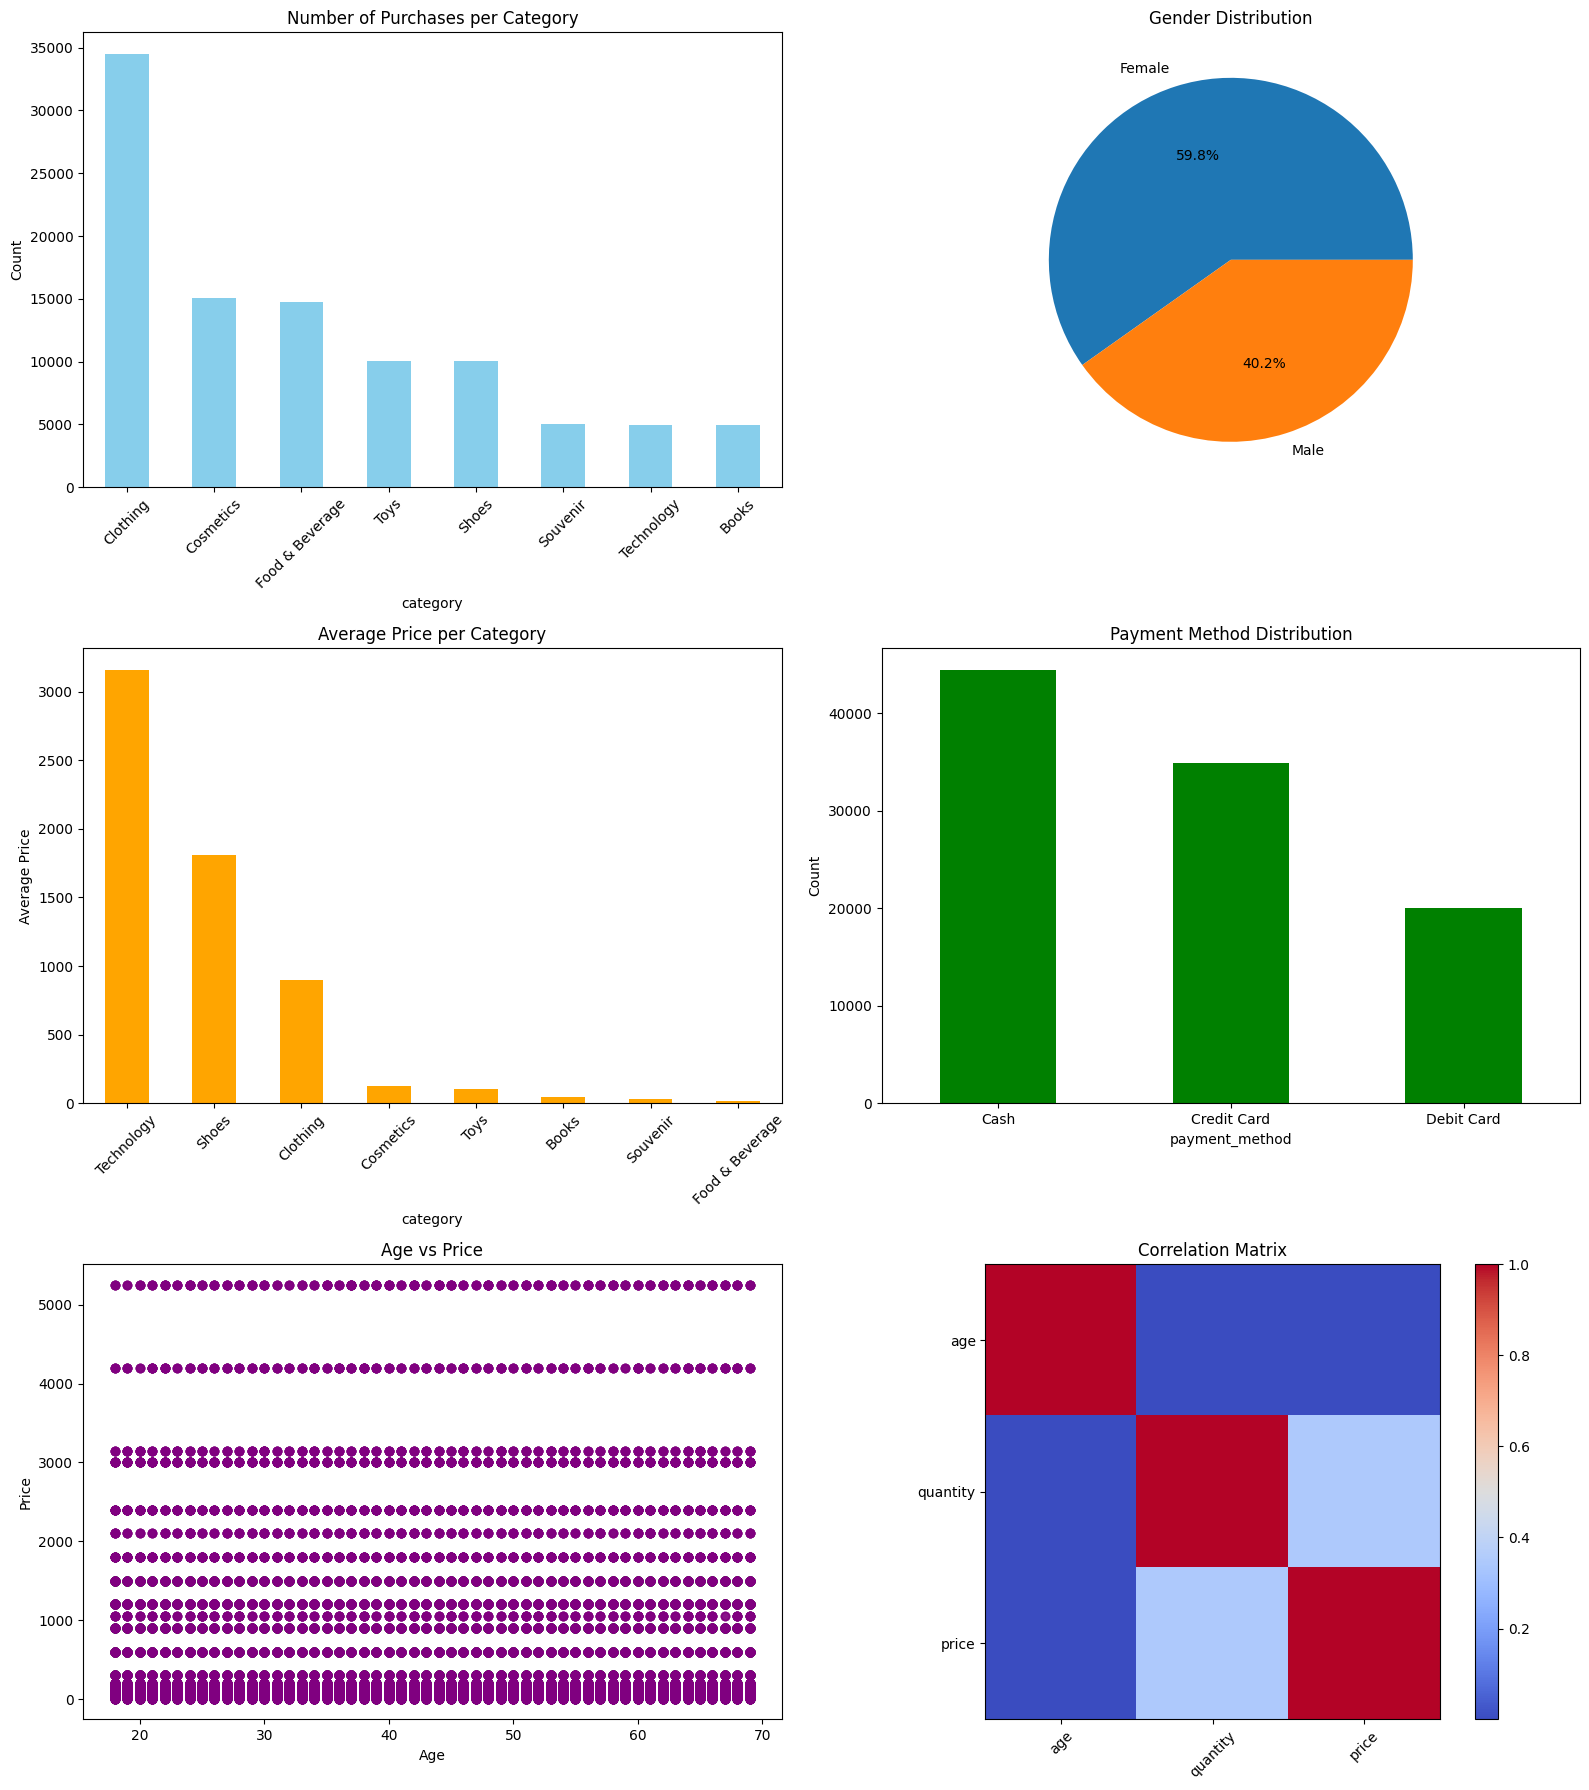

In [26]:
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Category distribution
train['category'].value_counts().plot(kind='bar', ax=axes[0,0], color='skyblue')
axes[0,0].set_title('Number of Purchases per Category')
axes[0,0].set_ylabel('Count')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Gender distribution
train['gender'].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=axes[0,1])
axes[0,1].set_title('Gender Distribution')
axes[0,1].set_ylabel('')

# 3. Average price per category
avg_price = train.groupby('category')['price'].mean().sort_values(ascending=False)
avg_price.plot(kind='bar', ax=axes[1,0], color='orange')
axes[1,0].set_title('Average Price per Category')
axes[1,0].set_ylabel('Average Price')
axes[1,0].tick_params(axis='x', rotation=45)

# 4. Payment method distribution
train['payment_method'].value_counts().plot(kind='bar', ax=axes[1,1], color='green')
axes[1,1].set_title('Payment Method Distribution')
axes[1,1].set_ylabel('Count')
axes[1,1].tick_params(axis='x', rotation=0)

# 5. Age vs Price scatter
axes[2,0].scatter(train['age'], train['price'], alpha=0.3, color='purple')
axes[2,0].set_title('Age vs Price')
axes[2,0].set_xlabel('Age')
axes[2,0].set_ylabel('Price')

# 6. Correlation heatmap
numeric_cols = train[['age', 'quantity', 'price']]
correlation = numeric_cols.corr()
im = axes[2,1].imshow(correlation, cmap='coolwarm', interpolation='nearest')
axes[2,1].set_xticks(range(len(correlation)))
axes[2,1].set_yticks(range(len(correlation)))
axes[2,1].set_xticklabels(correlation.columns, rotation=45)
axes[2,1].set_yticklabels(correlation.columns)
axes[2,1].set_title('Correlation Matrix')
fig.colorbar(im, ax=axes[2,1])

plt.tight_layout()
plt.show()

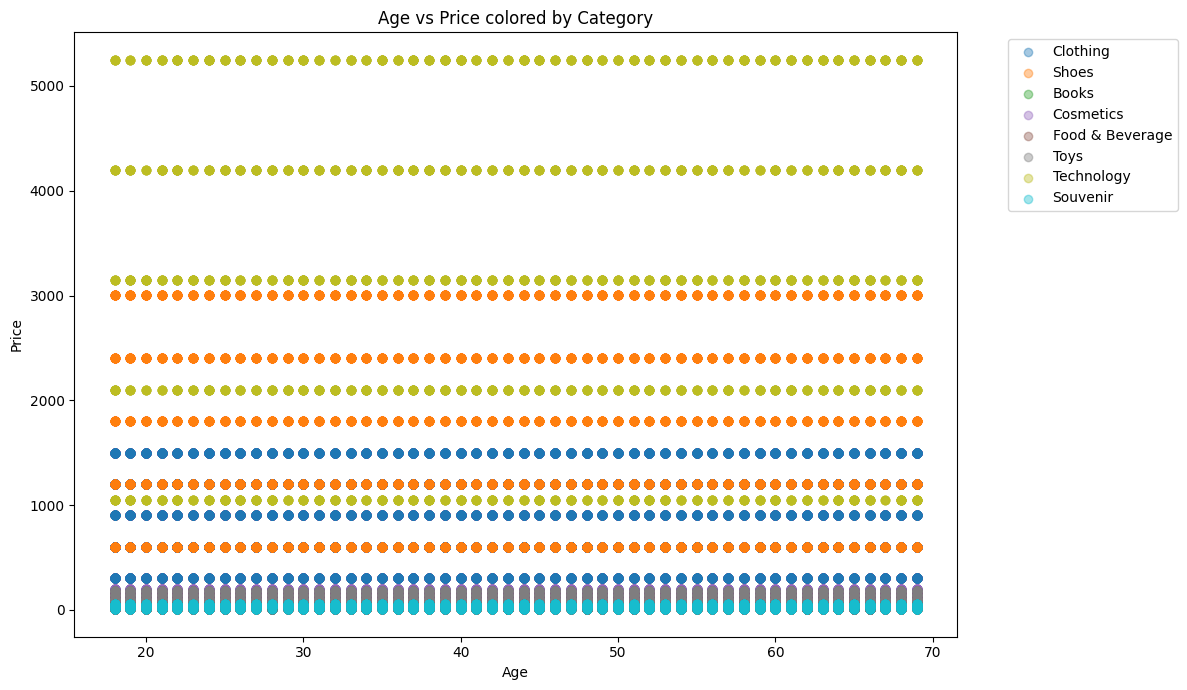

In [27]:
plt.figure(figsize=(12,7))
categories = train['category'].unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(categories)))

for cat, color in zip(categories, colors):
    subset = train[train['category'] == cat]
    plt.scatter(subset['age'], subset['price'], alpha=0.4, label=cat, color=color)

plt.xlabel('Age')
plt.ylabel('Price')
plt.title('Age vs Price colored by Category')
plt.legend(bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()